# 16 Final evaluation

In [1]:
import sys, pathlib, json, warnings; warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from IPython.display import Image, display
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})
def table(name):
    p = ROOT / 'reports' / 'tables' / name
    return pd.read_csv(p) if p.exists() else None

In [2]:
m = table('master_results.csv'); m.round(3).head(20) if m is not None else 'run scripts/final_evaluation.py'

,model,pr_auc,pr_auc_ci_lo,pr_auc_ci_hi,roc_auc,recall_budget,precision_budget,f1_budget,mcc_budget,fpr_budget,precision_at_100,recall_at_500,ndcg_at_1000,expected_cost_budget,prevented_ratio
0,presage:concat,0.982,0.964,0.990,1.000,0.977,0.752,0.850,0.856,0.002,1.00,0.990,0.997,3894.195,0.998
1,xgboost_tabular+graph_full,0.977,0.954,0.989,1.000,0.971,0.747,0.844,0.851,0.002,1.00,0.984,0.996,4146.243,0.997
2,catboost_tabular+graph_full,0.976,0.958,0.986,1.000,0.968,0.744,0.842,0.848,0.002,1.00,0.981,0.994,4288.575,0.996
3,presage:no_beh,0.960,0.919,0.979,0.996,0.958,0.737,0.833,0.839,0.002,1.00,0.965,0.976,5199.387,0.992
4,graph_hgt,0.959,0.927,0.976,0.999,0.955,0.734,0.830,0.837,0.002,1.00,0.961,0.983,5383.817,0.991
5,catboost_tabular+graph_struct,0.954,0.926,0.972,0.999,0.942,0.725,0.819,0.825,0.002,1.00,0.968,0.985,4442.028,0.996
6,catboost_all_tabular,0.951,0.928,0.966,0.999,0.939,0.722,0.816,0.822,0.002,1.00,0.961,0.980,4611.503,0.995
7,random_forest_tabular+graph_full,0.951,0.921,0.967,0.999,0.952,0.732,0.827,0.834,0.002,1.00,0.971,0.988,4238.169,0.996
8,xgboost_tabular+graph_struct,0.948,0.907,0.969,0.999,0.952,0.732,0.827,0.834,0.002,1.00,0.958,0.979,4142.875,0.997
9,presage:attention,0.943,0.905,0.964,0.999,0.952,0.732,0.827,0.834,0.002,1.00,0.961,0.970,5850.695,0.989


### APP-specific results (simulated money; operating policy chosen by expected cost on validation data)

In [3]:
a = table('app_specific_metrics.csv'); a.T if a is not None else None

,0
model,presage:full
scam_payments,310
scam_detected_pre_payment,287
recall_pre_payment,0.925806
mule_accounts,79
mule_flagged_before_first_victim_payment,74
mule_flagged_before_report_confirmation,75
mean_warning_lead_days,3.047227
simulated_gbp_prevented_expected,208369.341177
simulated_gbp_total_scam_value,222217.040417


### Error analysis (`reports/results/error_analysis.csv`)

In [4]:
e = pd.read_csv(ROOT/'reports/results/error_analysis.csv') if (ROOT/'reports/results/error_analysis.csv').exists() else None; e

,error_type,category,count,share,example_txn_ids,note
0,false_negative,scam to recruited genuine customer account (ol...,17,0.739130,317089 324022 330737 331065 332616,mule hides inside a real account
1,false_negative,scam beneficiary with limited history (<=2 pri...,3,0.130435,312849 328615 342065,cold-start beneficiary
2,false_negative,"post sudden-drift structuring (day>=100, small...",20,0.869565,328615 330737 331065 332616 342065,strategy change
3,false_negative,cross-bank scam payment,17,0.739130,312849 324022 331065 332616 342065,partial visibility
4,false_negative,low-value purchase scam,1,0.043478,328615,small amounts blend in
5,false_negative,romance scam (repeat moderate payments),11,0.478261,317089 324022 330737 344493 351349,payments resemble habitual transfers
6,false_negative,other,0,0.000000,NaN,NaN
7,false_positive,legitimate large first-time transfer (new paye...,38,0.160338,317301 317763 323884 325976 331615,house deposit / family transfer pattern
8,false_positive,legitimate payment to a young beneficiary account,0,0.000000,NaN,new business / neo-bank account
9,false_positive,payment from a new device,11,0.046414,318635 319456 324127 334097 334293,device upgrade


### Streaming demo

In [5]:
p = ROOT/'reports/results/streaming_demo.json'; print(open(p).read() if p.exists() else 'run streaming/run_demo.py')

{
 "events": 20000,
 "scored": 15981,
 "wall_s": 540.8293636610006,
 "throughput_eps": 36.98024061529374,
 "latency_ms_p50": 31.381566999698407,
 "latency_ms_p95": 64.05943200024922,
 "latency_ms_p99": 71.60817960011629,
 "alerts": 127,
 "alert_rate": 0.007946936987672862,
 "frauds_in_stream": 63,
 "frauds_intervened_pre_payment": 63,
 "recall_any_intervention": 1.0,
 "holds": 76,
 "precision_of_hold": 0.7763157894736842,
 "transport": "in-memory",
 "note": "payments are scored BEFORE settlement in event order; values simulated"
}


### Cross-dataset / real-data benchmarks

In [6]:
r = table('real_datasets.csv'); r.round(3) if r is not None else None

,dataset,feature_set,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,recall,precision,f1,f2,mcc,fpr,test_rows,test_positives,test_prevalence
0,PaySim,txn_only,0.987,0.980,0.995,0.999,0.986,0.935,0.960,0.975,0.958,0.003,15283,579,0.038
1,PaySim,txn+behaviour+beneficiary,0.989,0.983,0.996,1.000,0.991,0.933,0.961,0.979,0.960,0.003,15283,579,0.038
2,PaySim,txn+behaviour+beneficiary+graph,0.988,0.981,0.994,0.999,0.984,0.936,0.960,0.974,0.958,0.003,15283,579,0.038
3,IBM-AML-HI-Small(enriched subsample),txn_only,0.631,0.547,0.752,0.488,0.377,0.690,0.487,0.414,0.115,0.265,126,77,0.611
4,IBM-AML-HI-Small(enriched subsample),txn+behaviour+beneficiary,0.985,0.965,1.000,0.985,0.909,0.986,0.946,0.923,0.874,0.020,126,77,0.611
5,IBM-AML-HI-Small(enriched subsample),txn+behaviour+beneficiary+graph,0.979,0.951,1.000,0.983,0.896,0.986,0.939,0.913,0.859,0.020,126,77,0.611
6,Elliptic,local features (166),0.782,0.591,0.866,0.918,0.732,0.670,0.700,0.719,0.679,0.025,16670,1083,0.065
7,Elliptic,local + 1-hop aggregated + degree,0.788,0.603,0.869,0.924,0.738,0.671,0.703,0.723,0.682,0.025,16670,1083,0.065


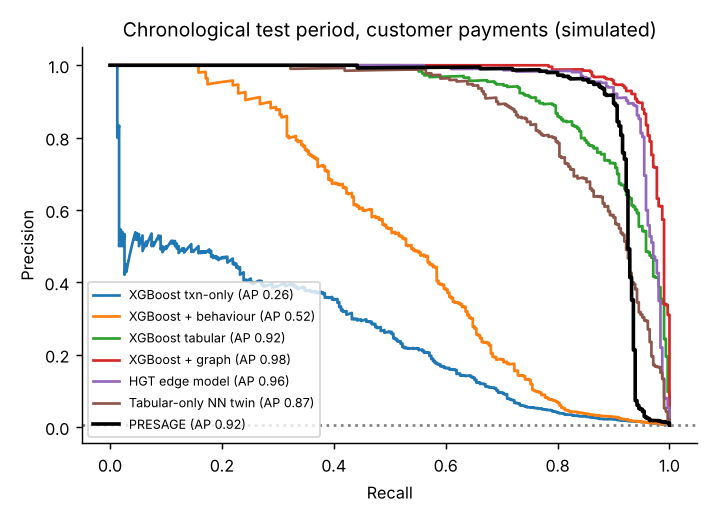

In [7]:
p = ROOT/'reports'/'figures'/'fig_pr_curves.png'; display(Image(str(p))) if p.exists() else None

See `reports/implementation_findings.md` for the written summary of what was and was not established.